# Seq2Seq Chatbot with Luong Attention

This notebook builds a chatbot that learns to reply from movie dialogue. It re-implements the PyTorch [Chatbot Tutorial](https://pytorch.org/tutorials/beginner/chatbot_tutorial.html) by Matthew Inkawhich and trains on the [Cornell Movie-Dialogs Corpus](https://www.cs.cornell.edu/~cristian/Cornell_Movie-Dialogs_Corpus.html).

The model is a sequence-to-sequence (seq2seq) network. A GRU **encoder** reads the input sentence. A GRU **decoder** with **Luong attention** writes the reply one word at a time.

## Pipeline

```
utterances.jsonl  (304,713 lines of dialogue)
   │  1. pair every line with the next line
   ▼
221,282 sentence pairs
   │  2. clean the text, filter by length and word frequency, build the vocabulary
   ▼
53,131 pairs + a vocabulary of 7,836 words
   │  3. pad and stack into batch tensors
   ▼
input (L, B), lengths (B,), target (L', B), mask (L', B)
   │
   ├──► 4. encoder: bidirectional GRU ──► outputs (L, B, H), hidden (4, B, H)
   │                                          │
   │         previous word (1, B) ──► 5. decoder GRU (one step) + attention
   │                                          │
   │                                  word probabilities (B, V)
   │                     ┌────────────────────┴────────────────────┐
   ▼                     ▼                                         ▼
          6. training: loss and backpropagation        7. inference: take the best word
             next input = the correct word                next input = its own output
```

## Notation

| Symbol | Meaning | Value |
| --- | --- | --- |
| `L` | words in the longest sentence of a batch, including EOS | at most 10 |
| `B` | sentences in a batch | 64 in training |
| `H` | hidden size of the GRUs | 500 |
| `V` | vocabulary size, including PAD, SOS and EOS | 7,836 |


## Source and changes

The data pipeline, the model and the figures come from the PyTorch Chatbot Tutorial. That tutorial borrows code from:

- Yuan-Kuei Wu's pytorch-chatbot: <https://github.com/ywk991112/pytorch-chatbot>
- Sean Robertson's practical-pytorch seq2seq-translation example: <https://github.com/spro/practical-pytorch/tree/master/seq2seq-translation>
- FloydHub's Cornell Movie Corpus preprocessing code: <https://github.com/floydhub/textutil-preprocess-cornell-movie-corpus>

These parts are different from the tutorial:

| Where | Tutorial | This notebook | Why |
| --- | --- | --- | --- |
| Everywhere | camelCase names, such as `loadLinesAndConversations` | `snake_case` names | PEP 8 |
| 1.1, 1.2 | `encoding='iso-8859-1'` | `encoding='utf-8'` | `utterances.jsonl` is pure ASCII, so the result is the same |
| 1.2 | dict keys `lineID`, `characterID`, `conversationID`, `movieID` | `line_id`, `character_id`, `conversation_id`, `movie_id` | Same naming rule |
| 2.2 | `readVocs` returns an empty `Voc` and the pairs | `read_pairs` returns only the pairs; `build_voc` creates and fills the `Voc` | One function, one job |
| 2.2 | `loadPrepareData(corpus, corpus_name, datafile, save_dir)` | `load_prepare_data(corpus_name, data_file)` | Two parameters were never used |
| 4.1, 5.2 | `nn.GRU(hidden_size, hidden_size, ...)` | `nn.GRU(embedding.embedding_dim, hidden_size, ...)` | The first argument is the word-vector size, not the state size |

Checked: the changed functions give the same output as the tutorial's functions on the same data. With the tutorial's trained weights, this model gives the same replies as the tutorial's code on six test sentences.


In [3]:
# Imports and device
import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F
import csv
import random
import re
import os
import unicodedata
import itertools
import json

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")


Using mps device


# 1. Raw lines → sentence pairs

**Goal:** turn `utterances.jsonl` into a text file in which every line is `input sentence <TAB> response sentence`.

Each line of the corpus is one utterance:

```
{"id": "L871", "conversation_id": "L870", "speaker": "u2", "text": "No", "meta": {"movie_id": "m0", ...}, "reply-to": "L870", ...}
```

```
utterances.jsonl                   grouped by conversation_id,        every line paired
(reverse order)                    back in speaking order             with the next line

L872  "Okay -- you're gonna ..."    L870  "I'm kidding. ..."           (L870 → L871)
L871  "No"                     →    L871  "No"                    →    (L871 → L872)
L870  "I'm kidding. ..."            L872  "Okay -- you're gonna ..."
```

- The lines of one conversation are stored in reverse order. `insert(0, ...)` puts them back in speaking order.
- A conversation with *n* lines gives *n* − 1 pairs.
- Counts: 304,713 utterances, 83,097 conversations, 221,282 pairs.
- A pair is "previous line → next line". It is not always "question → answer": only 30.41% of the inputs end with `?`. So the model learns how a movie character continues a conversation.
- In 982 pairs (0.44%) both lines are spoken by the same character.


In [4]:
# 1.1 Paths, and a look at the raw data
def print_lines(file, n=10):
    with open(file, 'rb') as f:
        for i in range(n):
            line = f.readline()
            print(line.decode('utf-8'))

corpus = "data/movie-corpus"
raw_utterances = os.path.join(corpus, "utterances.jsonl")
print_lines(raw_utterances, n=10)


{"id": "L1045", "conversation_id": "L1044", "text": "They do not!", "speaker": "u0", "meta": {"movie_id": "m0", "parsed": [{"rt": 1, "toks": [{"tok": "They", "tag": "PRP", "dep": "nsubj", "up": 1, "dn": []}, {"tok": "do", "tag": "VBP", "dep": "ROOT", "dn": [0, 2, 3]}, {"tok": "not", "tag": "RB", "dep": "neg", "up": 1, "dn": []}, {"tok": "!", "tag": ".", "dep": "punct", "up": 1, "dn": []}]}]}, "reply-to": "L1044", "timestamp": null, "vectors": []}

{"id": "L1044", "conversation_id": "L1044", "text": "They do to!", "speaker": "u2", "meta": {"movie_id": "m0", "parsed": [{"rt": 1, "toks": [{"tok": "They", "tag": "PRP", "dep": "nsubj", "up": 1, "dn": []}, {"tok": "do", "tag": "VBP", "dep": "ROOT", "dn": [0, 2, 3]}, {"tok": "to", "tag": "TO", "dep": "dobj", "up": 1, "dn": []}, {"tok": "!", "tag": ".", "dep": "punct", "up": 1, "dn": []}]}]}, "reply-to": null, "timestamp": null, "vectors": []}

{"id": "L985", "conversation_id": "L984", "text": "I hope so.", "speaker": "u0", "meta": {"movie_id"

In [5]:
# 1.2 Read the corpus into a dictionary of lines and a dictionary of conversations
def load_lines_and_conversations(file_name):
    lines = {}
    conversations = {}
    with open(file_name, 'r', encoding='utf-8') as f:
        for line in f:
            line_json = json.loads(line)
            line_obj = {
                'line_id': line_json['id'],
                'character_id': line_json['speaker'],
                'text': line_json['text']
            }
            lines[line_obj['line_id']] = line_obj

            conv_id = line_json['conversation_id']
            if conv_id not in conversations:
                conversations[conv_id] = {
                    'conversation_id': conv_id,
                    'movie_id': line_json['meta']['movie_id'],
                    'lines': [line_obj]
                }
            else:
                conversations[conv_id]['lines'].insert(0, line_obj)
    return lines, conversations


In [6]:
# 1.3 Pair every line with the next line of the same conversation
def extract_sentence_pairs(conversations):
    pairs = []
    for conv in conversations.values():
        lines = conv['lines']
        for i in range(len(lines) - 1):
            input_line = lines[i]['text'].strip()
            response = lines[i + 1]['text'].strip()
            if input_line and response:
                pairs.append([input_line, response])
    return pairs


In [7]:
# 1.4 Write the pairs to a tab-separated file
data_file = "data/formatted_movie_lines.txt"
lines, convs = load_lines_and_conversations(os.path.join(corpus, "utterances.jsonl"))
pairs = extract_sentence_pairs(convs)
with open(data_file, 'w', encoding='utf-8') as outputfile:
    writer = csv.writer(outputfile, delimiter='\t', lineterminator='\n')
    for pair in pairs:
        writer.writerow(pair)


# 2. Vocabulary, cleaning and filtering

**Goal:** a clean list of pairs (`pairs`) and a vocabulary (`voc`) that maps every word to a number.

```
221,282 pairs
   │  normalize_string: lower case, keep only letters and . ! ?
   │  filter_pairs:     keep a pair if both sentences have fewer than MAX_LENGTH = 10 words
   ▼
64,313 pairs, 18,079 different words
   │  trim_rare_words:  remove words seen fewer than MIN_COUNT = 3 times,
   │                    and every pair that contains one of them
   ▼
53,131 pairs, 7,833 words  (+ PAD, SOS, EOS = 7,836)
```


## 2.1 The vocabulary

The model works with numbers, not words. `Voc` keeps the mapping in both directions and counts each word. After `add_sentence("how are you")`:

```
word2index = {"how": 3, "are": 4, "you": 5}
word2count = {"how": 1, "are": 1, "you": 1}
index2word = {0: "PAD", 1: "SOS", 2: "EOS", 3: "how", 4: "are", 5: "you"}
num_words  = 6
```

- Indexes 0, 1, 2 are kept for three special tokens: `PAD` (padding), `SOS` (start of sentence), `EOS` (end of sentence).
- `trim(min_count)` rebuilds the dictionaries with the frequent words only. The indexes change, so it must run before sentences are turned into indexes.


In [8]:
# 2.1 Special tokens and the Voc class
PAD_token = 0
SOS_token = 1
EOS_token = 2

class Voc:
    def __init__(self, name):
        self.name = name
        self.trimmed = False
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "PAD", 1: "SOS", 2: "EOS"}
        self.num_words = 3  # Count SOS, EOS, PAD

    def add_sentence(self, sentence):
        for word in sentence.split(' '):
            self.add_word(word)

    def add_word(self, word):
        if word not in self.word2index:
            # new word
            self.word2index[word] = self.num_words
            self.word2count[word] = 1
            self.index2word[self.num_words] = word
            self.num_words += 1
        else:
            # old word
            self.word2count[word] += 1

    def trim(self, min_count):
        if self.trimmed:
            return
        self.trimmed = True

        # Keep only the words that appear at least min_count times.
        keep_words = [word for word, count in self.word2count.items() if count >= min_count]

        print(f"keep_words {len(keep_words)} / {len(self.word2index)} = {len(keep_words) / len(self.word2index):.4f}")

        # Reinitialize dictionaries
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "PAD", 1: "SOS", 2: "EOS"}
        self.num_words = 3  # Count default tokens

        # fill in the dictionaries with only the kept words
        for word in keep_words:
            self.add_word(word)


## 2.2 Cleaning and the length filter

```
"Don't go!  Please."   →   "don t go ! please ."
```

- `normalize_string` makes the text lower case, turns `.`, `!`, `?` into separate words and removes every other non-letter. The apostrophe is removed too, so `don't` becomes `don t`.
- `read_pairs` reads the file and cleans both sentences of every pair.
- `filter_pairs` keeps a pair only if both sentences have fewer than 10 words. This keeps 64,313 of 221,282 pairs (29%).
- `build_voc` counts the words of the kept pairs only.


In [9]:
# 2.2 Clean the text, filter by length, build the vocabulary
MAX_LENGTH = 10

def unicode_to_ascii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
    )

def normalize_string(s):
    s = unicode_to_ascii(s.lower().strip())
    # add space before punctuation
    s = re.sub(r"([.!?])", r" \1", s)
    # remove all non-letter characters except for punctuation included don't -> don t
    s = re.sub(r"[^a-zA-Z.!?]+", r" ", s)
    # remove extra spaces
    s = re.sub(r"\s+", r" ", s).strip()
    return s

def read_pairs(data_file):
    print("Reading lines...")
    # Read the file and split into lines
    with open(data_file, 'r', encoding='utf-8') as f:
        lines = f.read().strip().split('\n')

    # Split every line into a pair and normalize both sentences
    return [[normalize_string(s) for s in l.split('\t')] for l in lines]

def filter_pair(p):
    # Keep a pair only if both sentences have fewer than MAX_LENGTH words
    return len(p[0].split(' ')) < MAX_LENGTH and len(p[1].split(' ')) < MAX_LENGTH

def filter_pairs(pairs):
    return [pair for pair in pairs if filter_pair(pair)]

def build_voc(corpus_name, pairs):
    # Create the vocabulary and count every word in the given pairs
    voc = Voc(corpus_name)
    for pair in pairs:
        voc.add_sentence(pair[0])
        voc.add_sentence(pair[1])
    return voc

def load_prepare_data(corpus_name, data_file):
    print("Start preparing training data ...")
    pairs = read_pairs(data_file)
    print(f"Read {len(pairs)} sentence pairs")
    pairs = filter_pairs(pairs)
    print(f"Trimmed to {len(pairs)} sentence pairs")
    print("Counting words...")
    voc = build_voc(corpus_name, pairs)
    print(f"Counted words: {voc.num_words}")
    return voc, pairs


# Load/Assemble voc and pairs
corpus_name = "movie-corpus"
save_dir = os.path.join("data", "save")
voc, pairs = load_prepare_data(corpus_name, data_file)
# Print some pairs to validate
print("\npairs:")
for pair in pairs[:10]:
    print(pair)


Start preparing training data ...
Reading lines...
Read 221282 sentence pairs
Trimmed to 64313 sentence pairs
Counting words...
Counted words: 18082

pairs:
['they do to !', 'they do not !']
['she okay ?', 'i hope so .']
['wow', 'let s go .']
['what good stuff ?', 'the real you .']
['the real you .', 'like my fear of wearing pastels ?']
['do you listen to this crap ?', 'what crap ?']
['well no . . .', 'then that s all you had to say .']
['then that s all you had to say .', 'but']
['but', 'you always been this selfish ?']
['have fun tonight ?', 'tons']


## 2.3 Rare words

A word that appears once or twice cannot be learned, and a smaller vocabulary means a smaller embedding table and output layer. So words seen fewer than 3 times are removed.

| | Count | Share |
| --- | --- | --- |
| Rare word types | 10,246 of 18,079 | 56.7% of the vocabulary |
| Their occurrences | 13,794 of 684,045 | 2.0% of all words in the pairs |
| Pairs removed because of them | 11,182 of 64,313 | 17.4% of the pairs |

The cost: one rare word removes the whole pair, and the bot cannot read or write these words.


In [10]:
# 2.3 Remove rare words and the pairs that contain them
MIN_COUNT = 3
def trim_rare_words(voc, pairs, MIN_COUNT):
    voc.trim(MIN_COUNT)
    keep_pairs = []
    for pair in pairs:
        input_sentence = pair[0]
        output_sentence = pair[1]
        keep_input = all(word in voc.word2index for word in input_sentence.split(' '))
        keep_output = all(word in voc.word2index for word in output_sentence.split(' '))
        if keep_input and keep_output:
            keep_pairs.append(pair)

    print(f"Trimmed from {len(pairs)} pairs to {len(keep_pairs)}, {len(keep_pairs) / len(pairs):.4f} of total")
    return keep_pairs

# Trim voc and pairs
pairs = trim_rare_words(voc, pairs, MIN_COUNT)

# Check: final result of station 2
print(f"\nPairs kept: {len(pairs)}")
print(f"Words in voc: {voc.num_words} (including PAD, SOS, EOS)")
print("\npairs:")
for pair in pairs[:10]:
    print(pair)


keep_words 7833 / 18079 = 0.4333
Trimmed from 64313 pairs to 53131, 0.8261 of total

Pairs kept: 53131
Words in voc: 7836 (including PAD, SOS, EOS)

pairs:
['they do to !', 'they do not !']
['she okay ?', 'i hope so .']
['wow', 'let s go .']
['what good stuff ?', 'the real you .']
['do you listen to this crap ?', 'what crap ?']
['well no . . .', 'then that s all you had to say .']
['then that s all you had to say .', 'but']
['but', 'you always been this selfish ?']
['have fun tonight ?', 'tons']
['hi .', 'looks like things worked out tonight huh ?']


# 3. Sentence pairs → batch tensors

**Goal:** turn a batch of pairs into four tensors.

| Name | Shape | Meaning |
| --- | --- | --- |
| `inp` | `(L, B)` | word indexes of the input sentences, short ones padded with 0 |
| `lengths` | `(B,)` | real length of every input sentence |
| `output` | `(L', B)` | word indexes of the response sentences |
| `mask` | `(L', B)` | `True` for a real word, `False` for padding |

Example with three input sentences (the indexes are made up; 2 is `EOS`, 0 is `PAD`):

```
"how are you ?"  →  [7, 12, 3, 6, 2]                    s0   s1   s2
"hello there ."  →  [5, 8, 4, 2]             t=0   [    7,   5,   9 ]
"hi"             →  [9, 2]                   t=1   [   12,   8,   2 ]
                                    →        t=2   [    3,   4,   0 ]
                                             t=3   [    6,   2,   0 ]
                                             t=4   [    2,   0,   0 ]

                                             shape (L, B) = (5, 3),  lengths = [5, 4, 2]
```

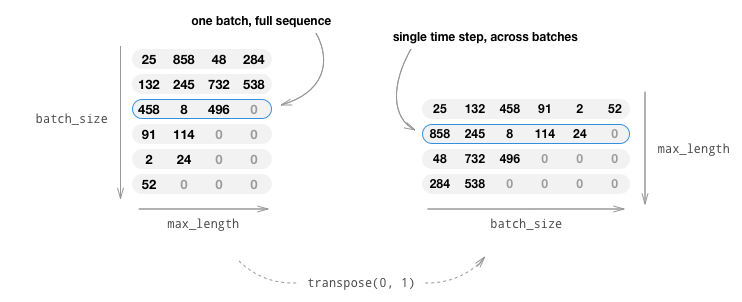

Figure from the PyTorch Chatbot Tutorial.

- Time comes first: **one column is one sentence**. `x[t]` is the word at step *t* of every sentence, which is what the decoder needs at each step.
- `zero_padding` uses `itertools.zip_longest`. It pads with 0 and does the transpose in one call.
- `binary_matrix` builds the mask. The loss uses it to ignore the padded positions.
- The batch is sorted by input length, longest first, because `pack_padded_sequence` in the encoder expects this order.


In [11]:
# 3.1 Turn sentences into padded tensors
def indexes_from_sentence(voc, sentence):
    return [voc.word2index[word] for word in sentence.split(' ')] + [EOS_token]

def zero_padding(l, fillvalue=PAD_token):
    return list(itertools.zip_longest(*l, fillvalue=fillvalue))

# Build the mask: 1 for a real word, 0 for padding, so the loss can ignore the padded positions.
def binary_matrix(l, value=PAD_token):
    return [[1 if x != value else 0 for x in seq] for seq in l]

def input_var(l, voc):
    indexes_batch = [indexes_from_sentence(voc, sentence) for sentence in l]
    lengths = torch.tensor([len(indexes) for indexes in indexes_batch])
    pad_list = zero_padding(indexes_batch)
    pad_var = torch.LongTensor(pad_list)
    return pad_var, lengths

def output_var(l, voc):
    indexes_batch = [indexes_from_sentence(voc, sentence) for sentence in l]
    max_target_len = max(len(indexes) for indexes in indexes_batch)
    pad_list = zero_padding(indexes_batch)
    mask = binary_matrix(pad_list)
    mask = torch.BoolTensor(mask)
    pad_var = torch.LongTensor(pad_list)
    return pad_var, mask, max_target_len

def batch_to_train_data(voc, pair_batch):
    # Sort the batch by the length of input sentences (descending order)
    pair_batch.sort(key=lambda x: len(x[0].split(" ")), reverse=True)
    input_batch, output_batch = [], []
    for pair in pair_batch:
        input_batch.append(pair[0])
        output_batch.append(pair[1])
    inp, lengths = input_var(input_batch, voc)
    output, mask, max_target_len = output_var(output_batch, voc)
    return inp, lengths, output, mask, max_target_len


In [12]:
# 3.2 Check on a small batch of 5 pairs
# Example for validation
small_batch_size = 5
batches = batch_to_train_data(voc, [random.choice(pairs) for _ in range(small_batch_size)])
input_variable, lengths, target_variable, mask, max_target_len = batches

print("input_variable:", input_variable)
print("lengths:", lengths)
print("target_variable:", target_variable)
print("mask:", mask)
print("max_target_len:", max_target_len)


input_variable: tensor([[  28,  317,   50,    8,  237],
        [ 819,    7,  385,   17,   14],
        [  11,   24, 1592,  789,    2],
        [  25,   35,   22,  291,    0],
        [1973,   75,  218,   14,    0],
        [  14,   10,    6,    2,    0],
        [   2,    2,    2,    0,    0]])
lengths: tensor([7, 7, 7, 6, 3])
target_variable: tensor([[  62, 2199,  317,   13,  103],
        [ 760,   14,   50,   19,    7],
        [  10,    2,   44,   14,   10],
        [  11,    0,    5,    2,    2],
        [ 265,    0,   14,    0,    0],
        [  62,    0,    2,    0,    0],
        [ 204,    0,    0,    0,    0],
        [ 760,    0,    0,    0,    0],
        [  10,    0,    0,    0,    0],
        [   2,    0,    0,    0,    0]])
mask: tensor([[ True,  True,  True,  True,  True],
        [ True,  True,  True,  True,  True],
        [ True,  True,  True,  True,  True],
        [ True, False,  True,  True,  True],
        [ True, False,  True, False, False],
        [ True, False

# 4. Encoder

**The seq2seq idea.** One network, the encoder, reads the input sentence. A second network, the decoder, writes the reply one word at a time.

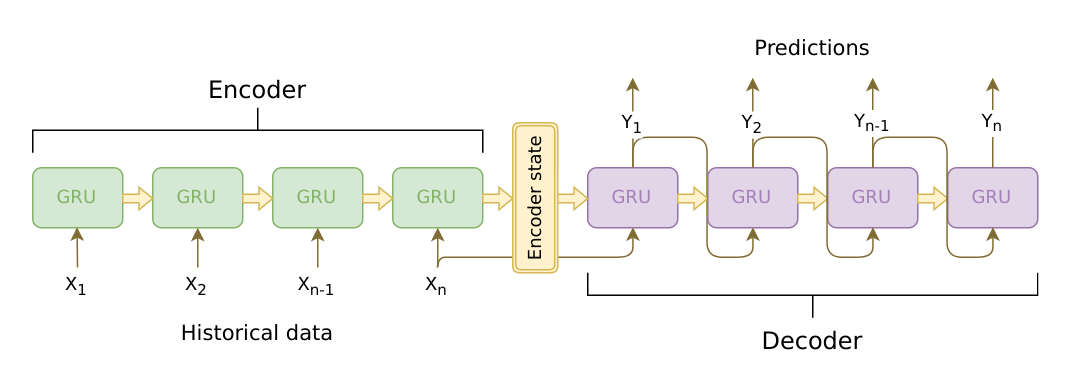

Figure: <https://jeddy92.github.io/JEddy92.github.io/ts_seq2seq_intro/>

**What the encoder does**

```
input_seq (L, B)                   word indexes
  → embedding                      (L, B, 500)     every index becomes a vector
  → pack_padded_sequence           padding is removed, so the GRU never reads it
  → bidirectional GRU, 2 layers    outputs (L, B, 1000), hidden (4, B, 500)
  → pad_packed_sequence            back to a normal tensor
  → first half + second half       outputs (L, B, 500)
```

**Bidirectional** means two GRUs read the same sentence, one from left to right and one from right to left. After each word a GRU updates its state (500 numbers), which holds what it has read so far.

```
forward  GRU →    how ──► are ──► you
                   f0      f1      f2        f1: the state after reading "how are"
backward GRU ←    how ◄── are ◄── you
                   b0      b1      b2        b1: the state after reading "you are"

output for "are" = [ f1 (500 numbers) | b1 (500 numbers) ]
```

- Every word gets both states, so it knows its left and its right context. The two halves are then added, which brings the size back to 500, the same as the decoder state.
- Bidirectional is a choice (`bidirectional=True`). The encoder can use it because the whole input sentence is known. The decoder cannot, because the later words do not exist yet.

**The two results**

| | What it is | Shape | Used by |
| --- | --- | --- | --- |
| `outputs` | the state at every word (top layer) | `(L, B, 500)` | attention: the decoder looks back at every input word |
| `hidden` | the state after the last word (every layer and direction) | `(4, B, 500)` | the decoder's first state: the meaning of the whole sentence |

The 4 parts of `hidden` are in this order: layer 0 forward, layer 0 backward, layer 1 forward, layer 1 backward.

In `nn.GRU(embedding.embedding_dim, hidden_size, ...)` the first argument is the size of a word vector and the second is the size of the state. Both are 500 here.


In [13]:
# 4.1 Encoder
class EncoderRNN(nn.Module):
    def __init__(self, hidden_size, embedding, n_layers=1, dropout=0.0):
        super().__init__()
        self.n_layers = n_layers
        self.hidden_size = hidden_size
        self.embedding = embedding

        # input_size is the word-vector size; hidden_size is the size of the GRU state
        self.gru = nn.GRU(embedding.embedding_dim, hidden_size, n_layers,
                          dropout=(0 if n_layers == 1 else dropout), bidirectional=True)

    def forward(self, input_seq, input_lengths, hidden=None):
        # Convert word indexes to embeddings
        embedded = self.embedding(input_seq)
        # Pack padded batch of sequences for RNN module
        packed = nn.utils.rnn.pack_padded_sequence(embedded, input_lengths)
        # Forward pass through GRU
        outputs, hidden = self.gru(packed, hidden)
        # Unpack padding
        outputs, _ = nn.utils.rnn.pad_packed_sequence(outputs)
        # Sum bidirectional GRU outputs
        outputs = outputs[:, :, :self.hidden_size] + outputs[:, :, self.hidden_size:]
        # Return output and final hidden state(its understanding for the whole sentence)
        return outputs, hidden


In [14]:
# 4.2 Check: run the encoder on the small batch
hidden_size = 500
embedding_dim = 500
embedding = nn.Embedding(voc.num_words, embedding_dim)
enc = EncoderRNN(hidden_size, embedding, n_layers=2, dropout=0.1)
outputs, hidden = enc(input_variable, lengths)
print("Encoder outputs shape:", outputs.shape)
print("Encoder hidden shape:", hidden.shape)


Encoder outputs shape: torch.Size([7, 5, 500])
Encoder hidden shape: torch.Size([4, 5, 500])


# 5. Attention and decoder

The decoder writes **one word per call**. Before it chooses the word, it looks back at the encoder outputs and decides how much to take from each input word. This is attention.

```
input_step (1, B)                            the previous word
  → embedding + dropout                      (1, B, 500)
  → GRU, one direction, 2 layers             rnn_output (1, B, 500), hidden (2, B, 500)
  → Attn(rnn_output, encoder_outputs)        attention weights (B, 1, L)
  → weights × encoder_outputs  (bmm)         context (B, 1, 500)
  → concatenate [rnn_output, context]        (B, 1000)
  → Linear + tanh                            (B, 500)
  → Linear + softmax                         word probabilities (B, V)
```

Without attention the decoder would only have `hidden`, one summary of the whole sentence. For long sentences that summary loses detail.


## 5.1 Attention: a worked example

The input is `where are you from`, and the decoder is about to write a word. To keep the numbers small, the vectors here have 2 numbers instead of 500 (made-up values).

```
input words:         where     are      you      from
encoder outputs:     [3, 0]    [0, 1]   [0, 2]   [2, 0]
decoder state h_t:   [1, 0]

1. score (dot)         3         0        0        2      multiply element by element, then add
2. softmax            0.68      0.03     0.03     0.25    the attention weights; they sum to 1
3. weighted sum       0.68×[3,0] + 0.03×[0,1] + 0.03×[0,2] + 0.25×[2,0] = [2.55, 0.10]    the context
4. concatenate        [h_t, context] = [1, 0, 2.55, 0.10]  → linear layers → the next word
```

- Steps 1 and 2 are the `Attn` class. Steps 3 and 4 are in the decoder.
- The weights are computed again for every output word, because the decoder state `h_t` changes after each word.

Luong et al. (2015) give three ways to compute the score. $h_t$ is the decoder state and $\bar{h}_s$ is one encoder output.

| `method` | Score | Learned parameters |
| --- | --- | --- |
| `dot` (used here) | $h_t^\top \bar{h}_s$ | none |
| `general` | $h_t^\top W_a \bar{h}_s$ | one matrix |
| `concat` | $v_a^\top \tanh(W_a [h_t ; \bar{h}_s])$ | one matrix and one vector |

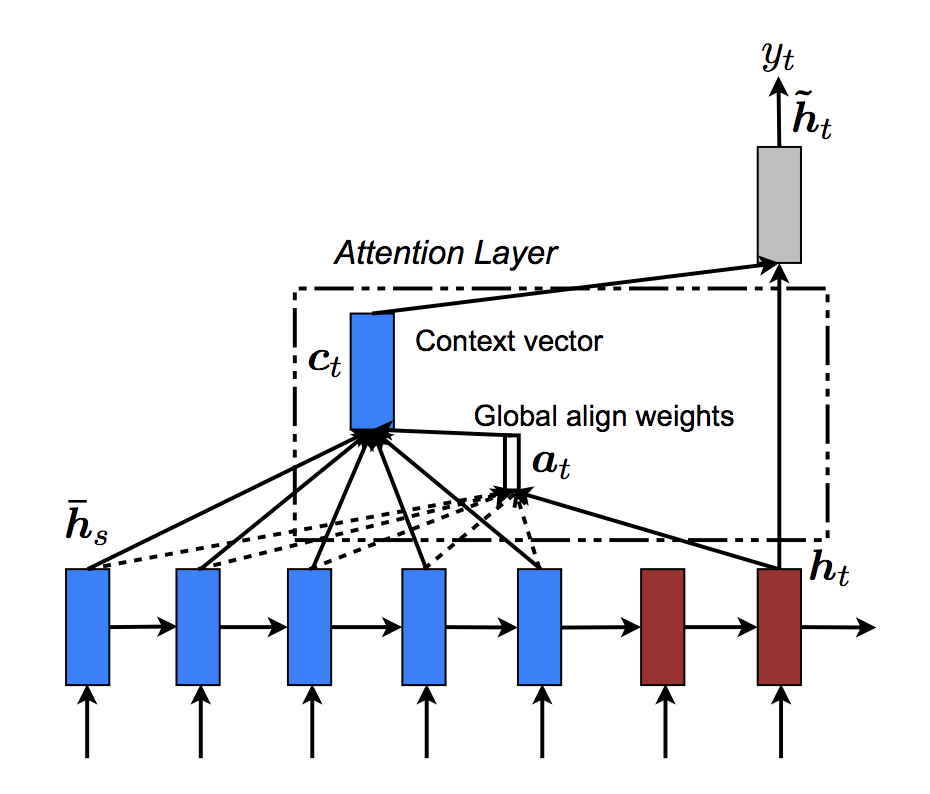

Figure from the PyTorch Chatbot Tutorial.


In [15]:
# 5.1 Luong attention layer
class Attn(nn.Module):
    def __init__(self, method, hidden_size):
        super().__init__()
        self.method = method
        self.hidden_size = hidden_size
        if self.method not in ['dot', 'general', 'concat']:
            raise ValueError(self.method, "is not an appropriate attention method.")
        if self.method == 'general':
            self.attn = nn.Linear(hidden_size, hidden_size)
        elif self.method == 'concat':
            self.attn = nn.Linear(hidden_size * 2, hidden_size)
            self.v = nn.Parameter(torch.FloatTensor(hidden_size))

    def dot_score(self, hidden, encoder_output):
        return torch.sum(hidden * encoder_output, dim=2)

    def general_score(self, hidden, encoder_output):
        energy = self.attn(encoder_output)
        return torch.sum(hidden * energy, dim=2)

    def concat_score(self, hidden, encoder_output):
        energy = self.attn(torch.cat((hidden.expand(encoder_output.size(0), -1, -1), encoder_output), 2)).tanh()
        return torch.sum(self.v * energy, dim=2)

    def forward(self, hidden, encoder_outputs):
        # Calculate the attention weights (energies) based on the given method
        if self.method == 'general':
            attn_energies = self.general_score(hidden, encoder_outputs)
        elif self.method == 'concat':
            attn_energies = self.concat_score(hidden, encoder_outputs)
        elif self.method == 'dot':
            attn_energies = self.dot_score(hidden, encoder_outputs)

        # Transpose max_length and batch_size dimensions
        attn_energies = attn_energies.t()

        # Return the softmax normalized probability scores (with added dimension)
        return F.softmax(attn_energies, dim=1).unsqueeze(1)


## 5.2 Decoder: inputs and outputs of one step

| Name | Shape | Meaning |
| --- | --- | --- |
| `input_step` | `(1, B)` | the previous word of every sentence |
| `last_hidden` | `(2, B, 500)` | the decoder state so far |
| `encoder_outputs` | `(L, B, 500)` | from the encoder |
| returns `output` | `(B, V)` | probability of each word being the next word |
| returns `hidden` | `(2, B, 500)` | the new decoder state |

- `output` is already a probability (softmax is applied), so the loss function takes `-log` itself.
- The decoder shares the `embedding` table with the encoder.
- `self.concat` is the name of a linear layer. It is not the same thing as `torch.cat`.


In [16]:
# 5.2 Decoder (one time step per call)
class LuongAttnDecoderRNN(nn.Module):
    def __init__(self, attn_model, embedding, hidden_size, output_size, n_layers=1, dropout=0.1):
        super().__init__()

        # Keep for reference
        self.attn_model = attn_model
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.n_layers = n_layers
        self.dropout = dropout

        # Define layers
        self.embedding = embedding
        self.embedding_dropout = nn.Dropout(dropout)
        self.gru = nn.GRU(embedding.embedding_dim, hidden_size, n_layers,
                          dropout=(0 if n_layers == 1 else dropout))
        self.concat = nn.Linear(hidden_size * 2, hidden_size)
        self.out = nn.Linear(hidden_size, output_size)

        self.attn = Attn(attn_model, hidden_size)

    def forward(self, input_step, last_hidden, encoder_outputs):
        # Note: we run this one step (word) at a time

        # Get embedding of current input word
        embedded = self.embedding(input_step)
        embedded = self.embedding_dropout(embedded)

        # Forward through unidirectional GRU
        rnn_output, hidden = self.gru(embedded, last_hidden)

        # Calculate attention weights from the current GRU output
        attn_weights = self.attn(rnn_output, encoder_outputs)

        # Multiply attention weights to encoder outputs to get new "weighted sum" context vector
        context = attn_weights.bmm(encoder_outputs.transpose(0, 1))

        # Concatenate weighted context vector and GRU output using Luong eq. 5
        rnn_output = rnn_output.squeeze(0)
        context = context.squeeze(1)
        concat_input = torch.cat((rnn_output, context), 1)
        concat_output = torch.tanh(self.concat(concat_input))

        # Predict next word using Luong eq. 6
        output = F.softmax(self.out(concat_output), dim=1)

        # Return output and final hidden state
        return output, hidden


In [17]:
# 5.3 Check: one decoder step
dec = LuongAttnDecoderRNN('dot', embedding, hidden_size, voc.num_words, n_layers=2, dropout=0.1)
decoder_input = torch.LongTensor([[SOS_token for _ in range(5)]])  # (1, 5)
decoder_hidden = hidden[:dec.n_layers]  # Use last (2, 5, 500)
out, h = dec(decoder_input, decoder_hidden, outputs)
print("Decoder output shape:", out.shape)
print("Decoder output sum (should be 1):", out.sum(dim=1))


Decoder output shape: torch.Size([5, 7836])
Decoder output sum (should be 1): tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<SumBackward1>)


# 6. Loss and training

**Goal:** make the model give a high probability to the correct next word.

One training iteration (one batch):

```
zero the gradients
encoder reads the whole batch                    → encoder_outputs, encoder_hidden
decoder input  = SOS for every sentence
decoder hidden = encoder_hidden[:decoder.n_layers]
for t in 0 .. max_target_len - 1:
    decoder writes one word                      → probabilities (B, V)
    loss += masked loss at step t
    next input = target word t                   (teacher forcing)
loss.backward() → clip the gradients → both optimizers take one step
```

At the start the loss is close to ln(7,836) = 8.97, which is the loss of a random guess.


## 6.1 Masked loss

Example for one time step, with 3 sentences and a vocabulary of 5 words:

```
inp: the model's probabilities                      target   mask
          w0     w1     w2     w3     w4
s0   [  0.10,  0.20,  0.60,  0.05,  0.05 ]             2      True
s1   [  0.70,  0.10,  0.10,  0.05,  0.05 ]             0      False   (padding)
s2   [  0.20,  0.20,  0.20,  0.30,  0.10 ]             4      True

gather: probability of the correct word       0.60     0.70     0.10
-log                                          0.51     0.36     2.30
keep where mask is True, then take the mean   (0.51 + 2.30) / 2 ≈ 1.41
```

- The lower the probability of the correct word, the larger the loss.
- Padded positions are not real words, so the mask removes them from the loss.


In [18]:
# 6.1 Masked loss
def mask_nll_loss(inp, target, mask):
    n_total = mask.sum()
    cross_entropy = -torch.log(torch.gather(inp, 1, target.view(-1, 1)).squeeze(1))
    loss = cross_entropy.masked_select(mask).mean()
    return loss.to(device), n_total.item()


## 6.2 One training iteration

**Teacher forcing.** With teacher forcing the next input is the correct word, even when the model's own guess was wrong.

```
target reply:   i   m   fine   .   EOS

training (teacher forcing)                inference
input:    SOS   i    m    fine   .        SOS   w1'  w2'  w3'  ...
output:   w1'   w2'  w3'  w4'    w5'      w1'   w2'  w3'  w4'  ...
```

Training is faster this way. But with `teacher_forcing_ratio = 1.0` the decoder never sees its own mistakes during training, and at inference it has to continue from them.

**Gradient clipping.** RNN gradients can become very large. When the gradient norm is above `clip`, it is scaled down, so one bad batch cannot throw the weights far away.

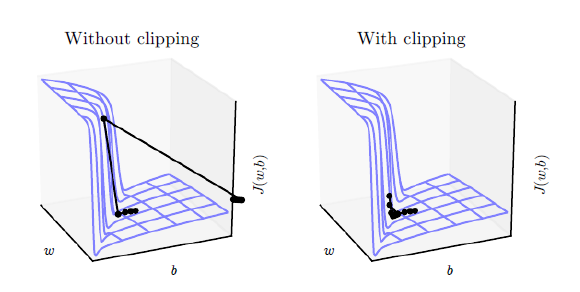

Figure: Goodfellow et al., *Deep Learning*, 2016. <https://www.deeplearningbook.org/>

**The decoder's first state.** `encoder_hidden[:decoder.n_layers]` takes the first two parts of `hidden`. These are the forward and backward states of encoder layer 0.


In [19]:
# 6.2 One training iteration (one batch)
def train(input_variable, lengths, target_variable, mask, max_target_len,
          encoder, decoder, embedding, encoder_optimizer, decoder_optimizer,
          batch_size, clip, max_length=MAX_LENGTH):
    # Zero gradients
    encoder_optimizer.zero_grad()
    decoder_optimizer.zero_grad()

    # Move to device
    input_variable = input_variable.to(device)
    target_variable = target_variable.to(device)
    mask = mask.to(device)

    # Initialize variables
    loss = 0
    print_losses = []
    n_totals = 0

    # Forward pass through encoder
    encoder_outputs, encoder_hidden = encoder(input_variable, lengths)

    # Prepare decoder input and hidden state
    decoder_input = torch.LongTensor([[SOS_token for _ in range(batch_size)]]).to(device)
    decoder_hidden = encoder_hidden[:decoder.n_layers]

    # Determine if we are using teacher forcing this iteration
    use_teacher_forcing = True if random.random() < teacher_forcing_ratio else False

    # Forward batch of sequences through decoder one time step at a time
    for t in range(max_target_len):
        decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden, encoder_outputs)

        # Teacher forcing: next input is current target
        if use_teacher_forcing:
            decoder_input = target_variable[t].view(1, -1)
        else:
            # No teacher forcing: next input is decoder's own current output
            _, topi = decoder_output.topk(1)
            decoder_input = topi.transpose(0, 1).detach()  # detach from history as input

        # Calculate and accumulate loss
        mask_loss, n_total = mask_nll_loss(decoder_output, target_variable[t], mask[t])
        loss += mask_loss
        print_losses.append(mask_loss.item() * n_total)
        n_totals += n_total

    # Backward pass
    loss.backward()

    # Clip gradients: gradients are modified in place
    nn.utils.clip_grad_norm_(encoder.parameters(), clip)
    nn.utils.clip_grad_norm_(decoder.parameters(), clip)

    # Adjust model weights
    encoder_optimizer.step()
    decoder_optimizer.step()

    return sum(print_losses) / n_totals


## 6.3 Training loop

- Every iteration uses 64 pairs drawn at random. It does not walk through the data epoch by epoch. 4,000 iterations see about 256,000 pairs, which is about 4.8 passes over the 53,131 pairs.
- Every `print_every` iterations the training loss is printed.
- Every `save_every` iterations a checkpoint is saved: the weights of the encoder, decoder and embedding, the state of both optimizers, the loss, the iteration number and the vocabulary. A checkpoint can be used to chat or to continue training.
- Only the training loss is reported. There is no validation set.


In [20]:
# 6.3 Training loop
def train_iters(model_name, voc, pairs, encoder, decoder, encoder_optimizer,
                decoder_optimizer, embedding, encoder_n_layers, decoder_n_layers,
                save_dir, n_iteration, batch_size, print_every, save_every,
                clip, corpus_name, load_filename):
    # Load batches for each iteration
    training_batches = [batch_to_train_data(voc, [random.choice(pairs) for _ in range(batch_size)])
                        for _ in range(n_iteration)]

    # Initializations
    start_iteration = 1
    if load_filename:
        checkpoint = torch.load(load_filename)
        start_iteration = checkpoint['iteration'] + 1

    print("Training...")
    for iteration in range(start_iteration, n_iteration + 1):
        training_batch = training_batches[iteration - 1]
        input_variable, lengths, target_variable, mask, max_target_len = training_batch

        # Run a training iteration with batch
        loss = train(input_variable, lengths, target_variable, mask, max_target_len,
                     encoder, decoder, embedding, encoder_optimizer, decoder_optimizer,
                     batch_size, clip)
        if iteration % print_every == 0:
            print(f"Iteration: {iteration}; Percent complete: {iteration / n_iteration * 100:.1f}%; Average loss: {loss:.4f}")

        if iteration % save_every == 0:
            directory = os.path.join(save_dir, model_name, corpus_name,
                                     f"{encoder_n_layers}-{decoder_n_layers}_{hidden_size}")
            if not os.path.exists(directory):
                os.makedirs(directory)
            torch.save({
                'iteration': iteration,
                'en': encoder.state_dict(),
                'de': decoder.state_dict(),
                'en_opt': encoder_optimizer.state_dict(),
                'de_opt': decoder_optimizer.state_dict(),
                'loss': loss,
                'voc_dict': voc.__dict__,
                'embedding': embedding.state_dict()
            }, os.path.join(directory, f"{iteration}_checkpoint.tar"))


# 7. Inference, configuration and running

Sections 4 to 6 only define classes and functions. This section builds the model, trains it and chats with it.

```
7.3 build    embedding, encoder, decoder   (random weights, or weights from a checkpoint)
7.4 train    train_iters → batch_to_train_data → train → encoder, decoder, mask_nll_loss
7.5 chat     evaluate_input → normalize_string → evaluate → GreedySearchDecoder → encoder, decoder
```

At inference there is no correct answer to feed in. The decoder's own output becomes its next input. This is the only difference from training.


## 7.1 Greedy search

At every step, take the word with the highest probability and use it as the next input (made-up numbers):

```
step 1:   i 0.41    you 0.22    what 0.08   ...    →  "i"
step 2:   m 0.35    don 0.30    am 0.05     ...    →  "m"
step 3:   fine 0.28 not 0.21    sorry 0.10  ...    →  "fine"
```

- It is simple and fast, but it always takes the safest word, so replies tend to be short and generic.
- The loop always runs `max_length` (10) steps. It does not stop when `EOS` is written.


In [21]:
# 7.1 Greedy search decoder
class GreedySearchDecoder(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder

    def forward(self, input_seq, input_length, max_length):
        # Forward input through encoder model
        encoder_outputs, encoder_hidden = self.encoder(input_seq, input_length)

        # Prepare decoder's initial input and hidden state
        decoder_hidden = encoder_hidden[:self.decoder.n_layers]
        decoder_input = torch.ones(1, 1, device=device, dtype=torch.long) * SOS_token

        # Initialize tensors to append decoded words to
        all_tokens = torch.zeros([0], device=device, dtype=torch.long)
        all_scores = torch.zeros([0], device=device)

        # Iteratively decode one word token at a time
        for _ in range(max_length):
            decoder_output, decoder_hidden = self.decoder(decoder_input, decoder_hidden, encoder_outputs)
            # Obtain most likely word token and its softmax score
            decoder_scores, decoder_input = torch.max(decoder_output, dim=1)
            # Record token and score
            all_tokens = torch.cat((all_tokens, decoder_input), dim=0)
            all_scores = torch.cat((all_scores, decoder_scores), dim=0)
            # Prepare current token to be next decoder input (add a dimension)
            decoder_input = torch.unsqueeze(decoder_input, 0)

        # Return collections of word tokens and scores
        return all_tokens, all_scores


## 7.2 Chat functions

`evaluate` turns one sentence into a reply:

```
"how are you ?"                          a cleaned sentence
   │ indexes_from_sentence
   ▼
[[7, 12, 3, 6, 2]]                       word indexes, as a batch of one sentence
   │ torch.LongTensor(...).transpose(0, 1)
   ▼
input_batch (L, 1), lengths = [5]        one column is one sentence
   │ searcher(input_batch, lengths, max_length)
   ▼
tokens                                   the index of every word of the reply
   │ voc.index2word
   ▼
["i", "m", "fine", ".", "EOS", ...]      the reply as words
```

(The indexes and the reply are an illustration.)

`evaluate_input` is the chat loop: read a line, stop on `q` or `quit`, clean it with `normalize_string` (the same cleaning as the training data), call `evaluate`, remove `EOS` and `PAD`, print the reply.

If the input has a word that is not in the vocabulary, the lookup raises `KeyError`. The loop prints `Error: Encountered unknown word.` and the bot gives no reply to that sentence.


In [22]:
# 7.2 Chat functions
def evaluate(encoder, decoder, searcher, voc, sentence, max_length=MAX_LENGTH):
    # Format input sentence as a batch
    indexes_batch = [indexes_from_sentence(voc, sentence)]
    lengths = torch.tensor([len(indexes) for indexes in indexes_batch])
    input_batch = torch.LongTensor(indexes_batch).transpose(0, 1).to(device)

    # Decode sentence with searcher
    tokens, scores = searcher(input_batch, lengths.to("cpu"), max_length)
    return [voc.index2word[token.item()] for token in tokens]

def evaluate_input(encoder, decoder, searcher, voc):
    input_sentence = ''
    while True:
        try:
            # Get input sentence
            input_sentence = input('> ')
            if input_sentence.lower() in ['q', 'quit']:
                break
            # Normalize sentence
            input_sentence = normalize_string(input_sentence)
            # Evaluate sentence
            output_words = evaluate(encoder, decoder, searcher, voc, input_sentence)
            # Format and print response sentence
            output_words[:] = [x for x in output_words if not (x == 'EOS' or x == 'PAD')]
            print('Bot:', ' '.join(output_words))

        except KeyError:
            print("Error: Encountered unknown word.")


## 7.3 Configuration and model

| Name | Value | Meaning |
| --- | --- | --- |
| `attn_model` | `'dot'` | attention score function (`'general'` and `'concat'` are the other two) |
| `hidden_size` | 500 | size of the GRU state |
| `embedding_dim` | 500 | size of a word vector |
| `encoder_n_layers`, `decoder_n_layers` | 2, 2 | number of GRU layers |
| `dropout` | 0.1 | dropout rate |
| `batch_size` | 64 | pairs per training batch |
| `load_filename` | `None` or a path | `None` starts from random weights; a path loads a checkpoint |

To load the tutorial's checkpoints (`../chat_bot/data/save/cb_model/movie-corpus/2-2_500/`), the layer names (`embedding`, `gru`, `concat`, `out`, `attn`) and the `Voc` attribute names must be the same as in the tutorial, and `embedding_dim` must be 500.


In [ ]:
# 7.3 Configuration and model
model_name = 'cb_handwritten'
attn_model = 'dot'           # the other choices are 'general' and 'concat'
hidden_size = 500
embedding_dim = 500          # word-vector size; must be 500 to load the old checkpoints
encoder_n_layers = 2
decoder_n_layers = 2
dropout = 0.1
batch_size = 64
# load_filename = None          # train from scratch
load_filename = os.path.join("..", "chat_bot", "data", "save", "cb_model",
                              "movie-corpus", "2-2_500", "4000_checkpoint.tar")   # chat with the old 4000-iteration model

# Load a checkpoint if load_filename is given
if load_filename:
    # map_location puts the saved tensors on the device we use now
    checkpoint = torch.load(load_filename, map_location=device)
    encoder_sd = checkpoint['en']
    decoder_sd = checkpoint['de']
    encoder_optimizer_sd = checkpoint['en_opt']
    decoder_optimizer_sd = checkpoint['de_opt']
    embedding_sd = checkpoint['embedding']
    # Use the vocabulary that the checkpoint was trained with
    voc.__dict__ = checkpoint['voc_dict']

print('Building encoder and decoder ...')
# Word embeddings, shared by the encoder and the decoder
embedding = nn.Embedding(voc.num_words, embedding_dim)
if load_filename:
    embedding.load_state_dict(embedding_sd)

# Build the two models from the classes defined above
encoder = EncoderRNN(hidden_size, embedding, encoder_n_layers, dropout)
decoder = LuongAttnDecoderRNN(attn_model, embedding, hidden_size, voc.num_words, decoder_n_layers, dropout)
if load_filename:
    encoder.load_state_dict(encoder_sd)
    decoder.load_state_dict(decoder_sd)

# Move the models to the selected device
encoder = encoder.to(device)
decoder = decoder.to(device)
print('Models built and ready to go!')


Building encoder and decoder ...
Models built and ready to go!


## 7.4 Training

| Name | Value | Meaning |
| --- | --- | --- |
| `clip` | 50.0 | largest gradient norm allowed |
| `teacher_forcing_ratio` | 1.0 | how often the correct word is used as the next input |
| `learning_rate` | 0.0001 | learning rate of the encoder |
| `decoder_learning_ratio` | 5.0 | the decoder learns 5 times faster |
| `n_iteration` | 200 | number of batches (the tutorial uses 4,000) |
| `print_every`, `save_every` | 10, 100 | how often to print the loss and save a checkpoint |

If a checkpoint from iteration 4,000 is loaded, this cell trains nothing, because the next iteration (4,001) is already above `n_iteration`.


In [24]:
# 7.4 Training
clip = 50.0
teacher_forcing_ratio = 1.0
learning_rate = 0.0001
decoder_learning_ratio = 5.0
n_iteration = 200
print_every = 10
save_every = 100

# Put the dropout layers in training mode
encoder.train()
decoder.train()

# One optimizer for each model; the decoder learns 5 times faster
print('Building optimizers ...')
encoder_optimizer = optim.Adam(encoder.parameters(), lr=learning_rate)
decoder_optimizer = optim.Adam(decoder.parameters(), lr=learning_rate * decoder_learning_ratio)
if load_filename:
    encoder_optimizer.load_state_dict(encoder_optimizer_sd)
    decoder_optimizer.load_state_dict(decoder_optimizer_sd)

# Run the training iterations
print("Starting Training!")
train_iters(model_name, voc, pairs, encoder, decoder, encoder_optimizer, decoder_optimizer,
            embedding, encoder_n_layers, decoder_n_layers, save_dir, n_iteration, batch_size,
            print_every, save_every, clip, corpus_name, load_filename)


Building optimizers ...
Starting Training!
Training...
Iteration: 10; Percent complete: 5.0%; Average loss: 6.5168
Iteration: 20; Percent complete: 10.0%; Average loss: 4.8990
Iteration: 30; Percent complete: 15.0%; Average loss: 4.6179
Iteration: 40; Percent complete: 20.0%; Average loss: 4.6895
Iteration: 50; Percent complete: 25.0%; Average loss: 4.4806
Iteration: 60; Percent complete: 30.0%; Average loss: 4.9483
Iteration: 70; Percent complete: 35.0%; Average loss: 4.3858
Iteration: 80; Percent complete: 40.0%; Average loss: 4.2138
Iteration: 90; Percent complete: 45.0%; Average loss: 4.3291
Iteration: 100; Percent complete: 50.0%; Average loss: 4.1776
Iteration: 110; Percent complete: 55.0%; Average loss: 4.4171
Iteration: 120; Percent complete: 60.0%; Average loss: 4.1418
Iteration: 130; Percent complete: 65.0%; Average loss: 4.4060
Iteration: 140; Percent complete: 70.0%; Average loss: 4.2798
Iteration: 150; Percent complete: 75.0%; Average loss: 4.1768
Iteration: 160; Percent c

## 7.5 Chat

The cell first prints the replies to four fixed test sentences, then opens the chat. Type `q` to stop.

Replies with the tutorial's 4,000-iteration checkpoint:

```
> hello ?                  Bot: hello . me . me . ?
> where are you from ?     Bot: i m in my bedroom . me .
> how are you doing ?      Bot: i m fine . me . .
> what is your name ?      Bot: my name . my name . me .
```

The first sentence of each reply is fine. The words after it were written after `EOS` (see the limitations below).


In [26]:
# 7.5 Chat
# Put the dropout layers in evaluation mode
encoder.eval()
decoder.eval()

# The search module that writes the reply one word at a time
searcher = GreedySearchDecoder(encoder, decoder)

# Fixed test sentences: keep these replies to compare with later experiments
test_sentences = ["hello ?", "where are you from ?", "how are you doing ?", "what is your name ?"]
for sentence in test_sentences:
    try:
        output_words = evaluate(encoder, decoder, searcher, voc, normalize_string(sentence))
        output_words = [x for x in output_words if not (x == 'EOS' or x == 'PAD')]
        print(f"> {sentence}\nBot: {' '.join(output_words)}")
    except KeyError:
        print(f"> {sentence}\nError: Encountered unknown word.")

# Chat with the bot (type q or quit to stop)
evaluate_input(encoder, decoder, searcher, voc)


> hello ?
Bot: i m a car . . .
> where are you from ?
Bot: i m a the car . . .
> how are you doing ?
Bot: i m a the car . . .
> what is your name ?
Bot: i m a car . . .
Bot: what ? s ? ? ?
Bot: what ? s ? ? ?
Bot: i m a car . . .
Bot: i m a the car . . .
Bot: what ? s ? ? ?
Bot: what ? s ? ? ?
Bot: i m a the car . . .
Bot: i m a car . . .
Error: Encountered unknown word.


# Limitations of this baseline

| # | Limitation | Evidence | Possible change |
| --- | --- | --- | --- |
| 1 | No validation set. Only the training loss is reported. | The training loop uses all 53,131 pairs. | Hold out the last 5% of the pairs (the last movies in the corpus). |
| 2 | Words written after the first `EOS` stay in the reply. | 486 of 500 sampled replies (97.2%). The mean reply length is 7.54 words, and 4.25 when cut at the first `EOS`. | Cut the reply at the first `EOS`. |
| 3 | One rare word removes the whole pair, and an unknown input word gets no reply. | 64,313 → 53,131 pairs (−17.4%), although rare words are only 2.0% of all word occurrences. | Replace rare and unknown words with an `UNK` token. |
| 4 | Greedy decoding always takes the safest word. | Not measured yet. | Beam search or sampling. |
| 5 | Apostrophes are removed: `don't` becomes `don t`. | See 2.2. | Keep contractions. |
| 6 | `teacher_forcing_ratio = 1.0`: the decoder never sees its own mistakes in training. | See 6.2. | A lower ratio. |
| 7 | The decoder's first state uses only encoder layer 0. | The order of `hidden` was checked by running PyTorch. | Add the forward and backward states of each layer. |
| 8 | 69 of the 53,131 pairs (0.13%) have more than two fields. | Lines with tabs or line breaks are quoted by `csv.writer` but split as raw text when read. | Read the file with `csv.reader`. |
